<a href="https://colab.research.google.com/github/pnamratha-07/PNamratha-4IK25CS136/blob/main/4IK25CS136_LP6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five rows: 
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Dataset shape: 
(1599, 12)

Column names: 
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing values: 
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide   

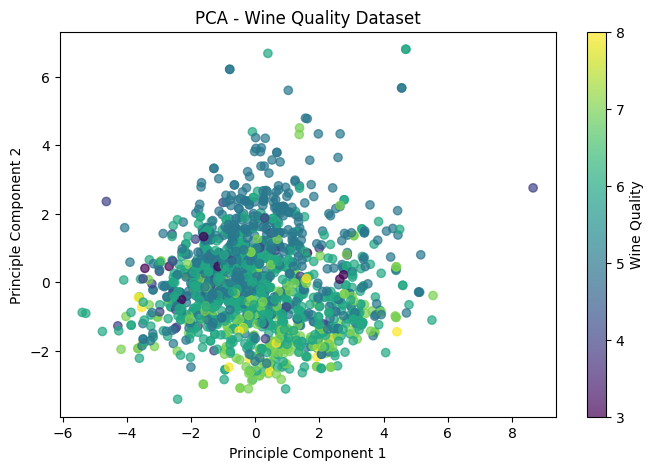

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("winequality-red.csv")

print("First five rows: ")
print(df.head())

print("\nDataset shape: ")
print(df.shape)

print("\nColumn names: ")
print(df.columns)

print("\nMissing values: ")
print(df.isnull().sum())

X = df.drop("quality", axis=1)
y = df["quality"]

normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized data (first 5 rows): ")
print(pd.DataFrame(
    X_normalized, columns = X.columns
).head().round(3))

standardizer = StandardScaler()
X_standardizer = standardizer.fit_transform(X)

print("\nStandardized data (first 5 rows): ")
print(pd.DataFrame(
    X_standardizer, columns = X.columns
).head().round(3))

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_standardizer)

print("\nPCA output (first 5 rows): ")
print(pd.DataFrame(
    X_pca, columns = ["PC1", "PC2"]
).head().round(3))

print("\nOriginal number of features: ", X.shape[1])
print("\nReduced number of features: ", X_pca.shape[1])

print("\nVarience retained by each component: ")
print(pca.explained_variance_ratio_.round(4))

print("Total varience retaiend: ",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.figure(figsize = (8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c = y, cmap = "viridis", alpha = 0.7)
plt.xlabel("Principle Component 1")
plt.ylabel("Principle Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label = "Wine Quality")
plt.show()